# Exploratory Data Analysis -- ECG Arrhythmia Classification

MIT-BIH Arrhythmia Database, AAMI EC57 five-class scheme, patient-independent
DS1/DS2 split. See `docs/methodology.md` for the full write-up; this notebook
just inspects the data the three models are trained on.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from build_dataset import build
from data_loader import load_record
from preprocessing import clean_signal, segment_beats
from utils import DS1_RECORDS, DS2_RECORDS, AAMI_CLASSES, BEAT_WINDOW_SEC, FS

%matplotlib inline

## 1. Raw vs. cleaned signal (record 100)

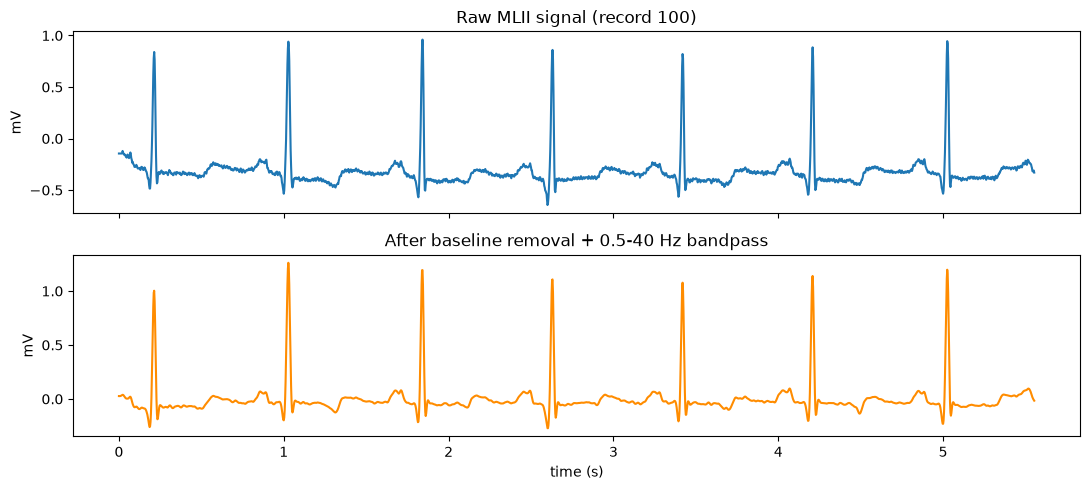

In [2]:
sig, fields, ann = load_record(100)
raw = sig[:, fields['sig_name'].index('MLII')]
cleaned = clean_signal(raw, fs=fields['fs'])

seg = slice(0, 2000)  # ~5.5 seconds
t = np.arange(seg.stop) / fields['fs']
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(t, raw[seg]); axes[0].set_title("Raw MLII signal (record 100)"); axes[0].set_ylabel("mV")
axes[1].plot(t, cleaned[seg], color="darkorange"); axes[1].set_title("After baseline removal + 0.5-40 Hz bandpass")
axes[1].set_ylabel("mV"); axes[1].set_xlabel("time (s)")
fig.tight_layout()
fig.savefig("../results/figures/eda_raw_vs_cleaned_signal.png", dpi=150)

## 2. Full MIT-BIH pipeline: load cached, segmented beats

In [3]:
data = build()
beats, labels, groups = data["beats"], data["labels"], data["groups"]
rr_prev, rr_next = data["rr_prev"], data["rr_next"]
print("Total beats:", len(beats))
pd.Series(labels).value_counts().reindex(AAMI_CLASSES)

Using cached dataset at /Users/sudhanshu.narvekar/Desktop/CCprojects/ecg-arrhythmia-pattern-recognition/data/beats_cache.npz
Total beats: 100692


N    90086
S     2781
V     7008
F      802
Q       15
Name: count, dtype: int64

## 3. Class distribution: overall, DS1, DS2

In [4]:
train_mask = np.isin(groups, DS1_RECORDS)
test_mask = np.isin(groups, DS2_RECORDS)

counts = pd.DataFrame({
    "overall": pd.Series(labels).value_counts(),
    "DS1_train": pd.Series(labels[train_mask]).value_counts(),
    "DS2_test": pd.Series(labels[test_mask]).value_counts(),
}).reindex(AAMI_CLASSES)
counts

,overall,DS1_train,DS2_test
N,90086,45847,44239
S,2781,944,1837
V,7008,3788,3220
F,802,414,388
Q,15,8,7


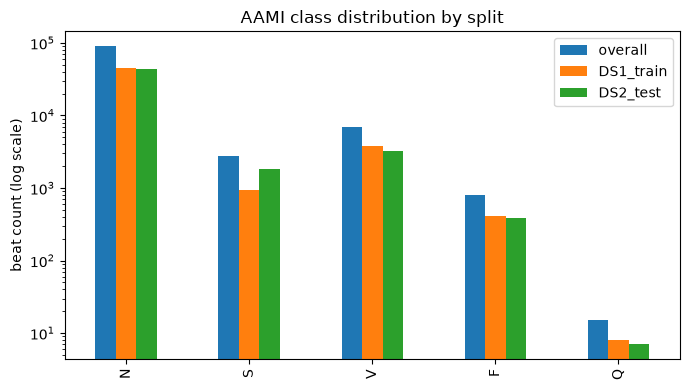

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind="bar", ax=ax, logy=True)
ax.set_ylabel("beat count (log scale)")
ax.set_title("AAMI class distribution by split")
fig.tight_layout()
fig.savefig("../results/figures/eda_class_distribution_by_split.png", dpi=150)

Classes N, S, V, F, Q are strongly imbalanced (N dominates with ~89% of
beats); this is why macro-F1 and per-class recall -- not raw accuracy -- are
the primary metrics used to compare the three models.

## 4. Sample segmented heartbeats per class

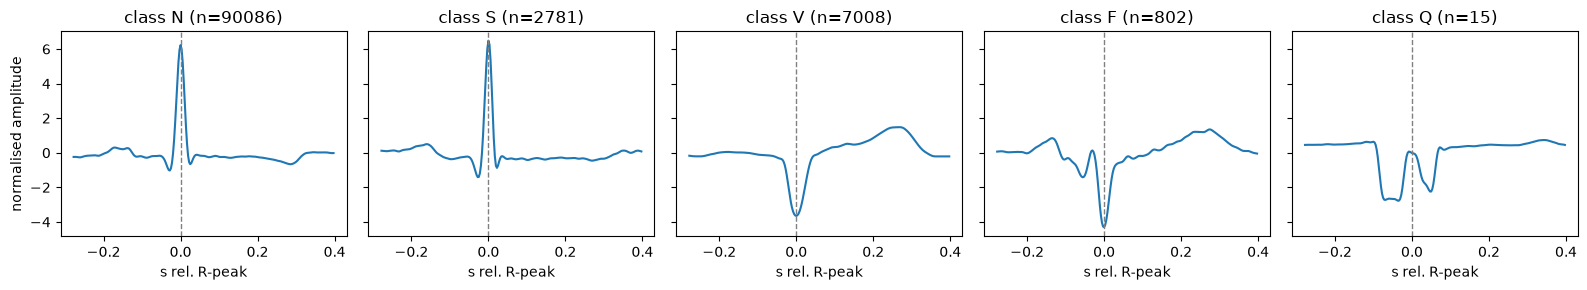

In [6]:
before = int(BEAT_WINDOW_SEC[0] * FS)
t_beat = (np.arange(beats.shape[1]) - before) / FS

fig, axes = plt.subplots(1, len(AAMI_CLASSES), figsize=(16, 3), sharey=True)
for ax, cls in zip(axes, AAMI_CLASSES):
    idx = np.where(labels == cls)[0]
    example = beats[idx[0]] if len(idx) else np.zeros_like(t_beat)
    ax.plot(t_beat, example)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"class {cls} (n={len(idx)})")
    ax.set_xlabel("s rel. R-peak")
axes[0].set_ylabel("normalised amplitude")
fig.tight_layout()
fig.savefig("../results/figures/eda_sample_beats_per_class.png", dpi=150)

## 5. RR interval / heart-rate-variability overview

mean RR = 0.789s  (~76 bpm),  SDNN = 0.395s


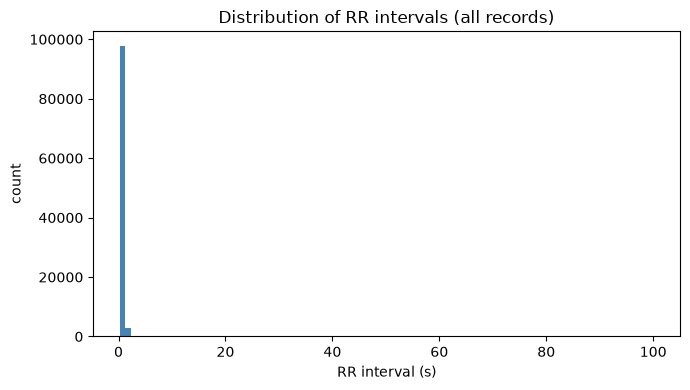

In [7]:
valid_rr = rr_prev[~np.isnan(rr_prev)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(valid_rr, bins=100, color="steelblue")
ax.set_xlabel("RR interval (s)")
ax.set_ylabel("count")
ax.set_title("Distribution of RR intervals (all records)")
fig.tight_layout()
fig.savefig("../results/figures/eda_rr_interval_distribution.png", dpi=150)
print(f"mean RR = {valid_rr.mean():.3f}s  (~{60/valid_rr.mean():.0f} bpm),  SDNN = {valid_rr.std():.3f}s")

## 6. Per-record beat yield

How many annotated beats per record survive segmentation (edge/invalid beats
dropped) -- see `results/per_record_summary.csv`, generated by
`build_dataset.py`.

In [8]:
summary = pd.read_csv("../results/per_record_summary.csv")
summary["yield_pct"] = 100 * summary["n_beats_kept"] / summary["n_annotations"]
summary.describe()

,record,n_beats_kept,n_annotations,yield_pct
count,44.000000,44.000000,44.000000,44.000000
mean,169.295455,2288.454545,2357.363636,97.093859
std,52.968872,471.310171,470.321517,4.705496
min,100.000000,1517.000000,1519.000000,77.945493
25%,114.750000,1933.750000,2032.000000,96.518829
50%,201.500000,2257.500000,2306.500000,98.758116
75%,216.000000,2601.250000,2675.250000,99.500090
max,234.000000,3362.000000,3400.000000,99.888641
